# Этап 1. Загрузка топологической карты

**Версия 2:** исправлена ориентация локальных карт (`row = x`, `col = y`).

Класс `TopoMapData` загружает граф локаций и локальные карты занятости.

- `graph.json` содержит вершины с `pose_for_visualization` и `edges`; поддерживается также вариант, когда рёбра хранятся в корневом ключе `edges`;
- `<node_id>/metadata.yaml` содержит параметр `resolution`;
- `<node_id>/occupancy.png` содержит карту занятости.

Целевые значения сетки: `0` — неизвестно, `1` — свободно, `2` — занято.


In [1]:
import json
from pathlib import Path

import numpy as np

try:
    import yaml
except ImportError:
    yaml = None

try:
    import cv2
except ImportError:
    cv2 = None

try:
    from PIL import Image
except ImportError:
    Image = None


def pose_to_matrix(x, y, theta):
    c = np.cos(theta)
    s = np.sin(theta)
    return np.array(
        [
            [c, -s, x],
            [s, c, y],
            [0.0, 0.0, 1.0],
        ],
        dtype=float,
    )


In [2]:
class TopoMapData:
    def __init__(self, base_path):
        self.base_path = Path(base_path).expanduser().resolve()
        self.graph_path = self.base_path / "graph.json"
        self.vertices = {}
        self.adjacency = {}
        self._map_cache = {}

    def load_graph(self):
        if not self.graph_path.exists():
            raise FileNotFoundError(f"graph.json не найден: {self.graph_path}")

        with self.graph_path.open("r", encoding="utf-8") as file:
            graph = json.load(file)

        raw_vertices = graph.get("vertices", {})
        if isinstance(raw_vertices, dict):
            vertex_items = sorted(
                (int(key), value) for key, value in raw_vertices.items()
            )
        else:
            vertex_items = list(enumerate(raw_vertices))

        root_edges = graph.get("edges")
        self.vertices = {}
        self.adjacency = {}

        for node_id, raw_vertex in vertex_items:
            pose = np.asarray(
                raw_vertex.get("pose_for_visualization", [0.0, 0.0, 0.0]),
                dtype=float,
            ).reshape(-1)
            pose = self._normalize_pose(pose)

            raw_edges = raw_vertex.get("edges")
            if raw_edges is None and root_edges is not None:
                raw_edges = self._get_root_edges(root_edges, node_id)

            edges = self._parse_edges(raw_edges)
            self.vertices[node_id] = {"pose": pose, "edges": edges}
            self.adjacency[node_id] = [edge["to"] for edge in edges]

        return self.vertices

    def load_local_map(self, node_id):
        node_id = int(node_id)
        if node_id in self._map_cache:
            resolution, grid = self._map_cache[node_id]
            return resolution, grid.copy()

        node_dir = self.base_path / str(node_id)
        metadata_path = node_dir / "metadata.yaml"
        occupancy_path = node_dir / "occupancy.png"

        if not node_dir.is_dir():
            raise FileNotFoundError(f"Папка локации не найдена: {node_dir}")
        if not occupancy_path.exists():
            raise FileNotFoundError(f"occupancy.png не найден: {occupancy_path}")

        metadata = self._load_metadata(metadata_path)
        resolution = float(metadata.get("resolution", 0.1))
        image = self._read_occupancy_image(occupancy_path)
        grid = self._to_occupancy_grid(image)

        self._map_cache[node_id] = (resolution, grid.copy())
        return resolution, grid

    def get_pose_matrix(self, node_id):
        pose = self.vertices[int(node_id)]["pose"]
        return pose_to_matrix(pose[0], pose[1], pose[2])

    def _get_root_edges(self, root_edges, node_id):
        if isinstance(root_edges, dict):
            return root_edges.get(str(node_id), root_edges.get(node_id, []))
        if isinstance(root_edges, (list, tuple)) and node_id < len(root_edges):
            candidate = root_edges[node_id]
            if isinstance(candidate, dict):
                return [candidate] if "to" in candidate else candidate
            if isinstance(candidate, (list, tuple)):
                if not candidate:
                    return []
                first = candidate[0]
                if np.isscalar(first) and len(candidate) >= 2:
                    return [
                        edge
                        for edge in root_edges
                        if isinstance(edge, (list, tuple))
                        and len(edge) >= 2
                        and int(edge[0]) == node_id
                    ]
                return candidate
        return []

    def _normalize_pose(self, pose):
        if pose.size == 2:
            return np.array([pose[0], pose[1], 0.0], dtype=float)
        if pose.size < 3:
            padded = np.zeros(3, dtype=float)
            padded[: pose.size] = pose
            return padded
        return pose[:3].astype(float, copy=True)

    def _parse_edges(self, raw_edges):
        if raw_edges is None:
            return []

        if isinstance(raw_edges, dict) and "to" in raw_edges:
            candidates = [raw_edges]
        elif isinstance(raw_edges, dict):
            candidates = []
            for target, value in raw_edges.items():
                if isinstance(value, dict):
                    item = dict(value)
                    item.setdefault("to", target)
                else:
                    item = {"to": target, "pose": value}
                candidates.append(item)
        elif isinstance(raw_edges, (list, tuple)):
            candidates = list(raw_edges)
        else:
            return []

        edges = []
        for candidate in candidates:
            edge = self._parse_edge(candidate)
            if edge is not None:
                edges.append(edge)
        return edges

    def _parse_edge(self, candidate):
        if isinstance(candidate, dict):
            if "to" not in candidate:
                return None
            target = int(candidate["to"])
            pose = candidate.get("pose")
        elif isinstance(candidate, (list, tuple)):
            if len(candidate) >= 4 and np.isscalar(candidate[0]):
                target = int(candidate[0])
                pose = candidate[1:4]
            elif len(candidate) >= 2:
                target = int(candidate[0])
                pose = candidate[1]
                if isinstance(pose, dict):
                    pose = pose.get("pose")
            else:
                return None
        else:
            return None

        pose_array = np.asarray(
            pose if pose is not None else [0.0, 0.0, 0.0],
            dtype=float,
        ).reshape(-1)
        return {"to": target, "pose": self._normalize_pose(pose_array)}

    def _load_metadata(self, metadata_path):
        if not metadata_path.exists():
            return {}
        text = metadata_path.read_text(encoding="utf-8")
        if yaml is not None:
            try:
                loaded = yaml.safe_load(text)
                if isinstance(loaded, dict):
                    return loaded
            except Exception:
                pass
        return self._parse_simple_yaml(text)

    def _parse_simple_yaml(self, text):
        result = {}
        for raw_line in text.splitlines():
            line = raw_line.strip()
            if not line or line.startswith("#") or ":" not in line:
                continue
            key, value = line.split(":", 1)
            key = key.strip()
            value = value.strip()
            if not key or not value:
                continue
            if value.lower() in {"true", "false"}:
                result[key] = value.lower() == "true"
                continue
            try:
                result[key] = float(value)
            except ValueError:
                result[key] = value.strip("'\"")
        return result

    def _read_occupancy_image(self, image_path):
        if cv2 is not None:
            image = cv2.imread(str(image_path), cv2.IMREAD_UNCHANGED)
            if image is None:
                raise ValueError(f"Не удалось прочитать изображение: {image_path}")
            if image.ndim == 3 and image.shape[2] == 3:
                image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            elif image.ndim == 3 and image.shape[2] == 4:
                image = cv2.cvtColor(image, cv2.COLOR_BGRA2RGBA)
            return image

        if Image is None:
            raise ImportError("Установите opencv-python или Pillow")

        with Image.open(image_path) as image:
            if image.mode == "P":
                image = image.convert("RGBA")
            return np.array(image)

    def _to_occupancy_grid(self, image):
        array = np.asarray(image)
        alpha = None

        if array.ndim == 3:
            if array.shape[2] == 4:
                alpha = array[..., 3]
            rgb = array[..., :3].astype(float)
            gray = (
                rgb[..., 0] * 0.299
                + rgb[..., 1] * 0.587
                + rgb[..., 2] * 0.114
            )
        else:
            gray = array.astype(float)

        if array.dtype == bool:
            gray = gray * 255.0

        max_value = float(np.nanmax(gray)) if gray.size else 0.0
        if np.issubdtype(array.dtype, np.floating) and max_value <= 1.0:
            gray = gray * 255.0
        elif max_value > 255.0:
            gray = gray / max(max_value, 1.0) * 255.0

        gray = np.clip(np.rint(gray), 0, 255).astype(np.uint8)
        unique_values = np.unique(gray)

        if unique_values.size > 0 and int(unique_values.max()) <= 2:
            grid = gray.astype(np.uint8)
        else:
            grid = np.zeros(gray.shape, dtype=np.uint8)
            grid[gray >= 220] = 1
            grid[gray <= 40] = 2

        if alpha is not None:
            grid[np.asarray(alpha) == 0] = 0

        return grid


In [3]:
from pathlib import Path

data_root = Path("2n8kARJN3HM")
if not (data_root / "graph.json").exists():
    candidates = sorted(Path(".").glob("*/graph.json"))
    if candidates:
        data_root = candidates[0].parent

topo_map = TopoMapData(data_root)
vertices = topo_map.load_graph()

print(f"Корневая папка: {topo_map.base_path}")
print(f"Вершин: {len(vertices)}")
print(f"Рёбер: {sum(len(vertex['edges']) for vertex in vertices.values())}")
print(f"Первые вершины: {list(vertices)[:5]}")


Корневая папка: /home/dmitry/explorer_view/2n8kARJN3HM
Вершин: 95
Рёбер: 252
Первые вершины: [0, 1, 2, 3, 4]


In [4]:
first_node = next(iter(vertices))

print(f"Вершина: {first_node}")
print(f"Поза: {vertices[first_node]['pose']}")
print(f"Исходящие рёбра: {vertices[first_node]['edges'][:2]}")
print("Матрица однородного преобразования:")
print(topo_map.get_pose_matrix(first_node))

resolution, grid = topo_map.load_local_map(first_node)
values, counts = np.unique(grid, return_counts=True)

print(f"resolution: {resolution}")
print(f"shape: {grid.shape}, dtype: {grid.dtype}")
print(f"значения сетки: {dict(zip(values.tolist(), counts.tolist()))}")


Вершина: 0
Поза: [-0.4175728  -2.68826921 -1.09942506]
Исходящие рёбра: [{'to': 1, 'pose': array([ 3.87751452, -3.37161212, -1.11701083])}]
Матрица однородного преобразования:
[[ 0.45410844  0.89094642 -0.4175728 ]
 [-0.89094642  0.45410844 -2.68826921]
 [ 0.          0.          1.        ]]
resolution: 0.1
shape: (360, 360), dtype: uint8
значения сетки: {0: 121250, 1: 7560, 2: 790}


In [5]:
loaded = {}

for node_id in vertices:
    resolution, grid = topo_map.load_local_map(node_id)
    loaded[node_id] = (resolution, grid.shape)

print(f"Загружено локальных карт: {len(loaded)}")
print(f"Уникальные resolution: {sorted({item[0] for item in loaded.values()})}")
print(f"Уникальные размеры: {sorted({item[1] for item in loaded.values()})}")


Загружено локальных карт: 95
Уникальные resolution: [0.1]
Уникальные размеры: [(360, 360)]


## Этап 2. Глобальная сшивка карт

Все локальные карты занятости вставляются в единую глобальную сетку по `pose_for_visualization`.

Важно: локальная карта хранится как массив `[x, y]`, то есть строка соответствует локальной оси `x` (вперёд), а столбец — локальной оси `y` (влево). Поэтому преобразование выполняется в три шага:

1. пиксели карты → локальные метры;
2. локальные метры → мировые координаты через `pose_to_matrix(x, y, theta)`;
3. мировые координаты → пиксели глобальной сетки.

Слияние выполняется поэлементной максимизацией: `0` — неизвестно, `1` — свободно, `2` — занято.


In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap


def grid_to_local_matrix(shape, resolution):
    height, width = shape
    cx, cy = width / 2.0, height / 2.0
    return np.array(
        [
            [0.0, resolution, -cy * resolution],
            [resolution, 0.0, -cx * resolution],
            [0.0, 0.0, 1.0],
        ],
        dtype=float,
    )


def local_to_grid_matrix(shape, resolution):
    height, width = shape
    cx, cy = width / 2.0, height / 2.0
    return np.array(
        [
            [0.0, 1.0 / resolution, cx],
            [1.0 / resolution, 0.0, cy],
            [0.0, 0.0, 1.0],
        ],
        dtype=float,
    )


def stitch_global_map(topo_map):
    resolution = None
    min_x = min_y = np.inf
    max_x = max_y = -np.inf
    for node_id in topo_map.vertices:
        x, y, _ = topo_map.vertices[node_id]["pose"]
        min_x = min(min_x, x)
        max_x = max(max_x, x)
        min_y = min(min_y, y)
        max_y = max(max_y, y)
        res, _ = topo_map.load_local_map(node_id)
        if resolution is None:
            resolution = res

    padding = 20.0
    world_min_x = min_x - padding
    world_max_x = max_x + padding
    world_min_y = min_y - padding
    world_max_y = max_y + padding

    width = int(np.ceil((world_max_x - world_min_x) / resolution))
    height = int(np.ceil((world_max_y - world_min_y) / resolution))
    global_grid = np.zeros((height, width), dtype=np.uint8)

    world_to_pixel = np.array(
        [
            [1.0 / resolution, 0.0, -world_min_x / resolution],
            [0.0, -1.0 / resolution, world_max_y / resolution],
            [0.0, 0.0, 1.0],
        ],
        dtype=float,
    )

    for node_id in topo_map.vertices:
        res, local_grid = topo_map.load_local_map(node_id)
        x, y, theta = topo_map.vertices[node_id]["pose"]
        matrix = (
            world_to_pixel
            @ pose_to_matrix(x, y, theta)
            @ grid_to_local_matrix(local_grid.shape, res)
        )
        warped = cv2.warpAffine(
            local_grid,
            matrix[:2].astype(np.float32),
            (width, height),
            flags=cv2.INTER_NEAREST,
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=0,
        )
        global_grid = np.maximum(global_grid, warped)

    params = {
        "resolution": resolution,
        "min_x": float(min_x),
        "max_x": float(max_x),
        "min_y": float(min_y),
        "max_y": float(max_y),
        "world_min_x": float(world_min_x),
        "world_max_x": float(world_max_x),
        "world_min_y": float(world_min_y),
        "world_max_y": float(world_max_y),
        "width": width,
        "height": height,
        "padding": padding,
    }
    return global_grid, params


def world_to_global_pixel(x, y, params):
    col = (x - params["world_min_x"]) / params["resolution"]
    row = (params["world_max_y"] - y) / params["resolution"]
    return row, col


Размер глобальной сетки: (599, 606)
Разрешение, м/пиксель: 0.1
Bounding box поз: x = [-6.94, 13.63], y = [-16.42, 3.39]
Значения сетки: {0: 205712, 1: 137138, 2: 20144}


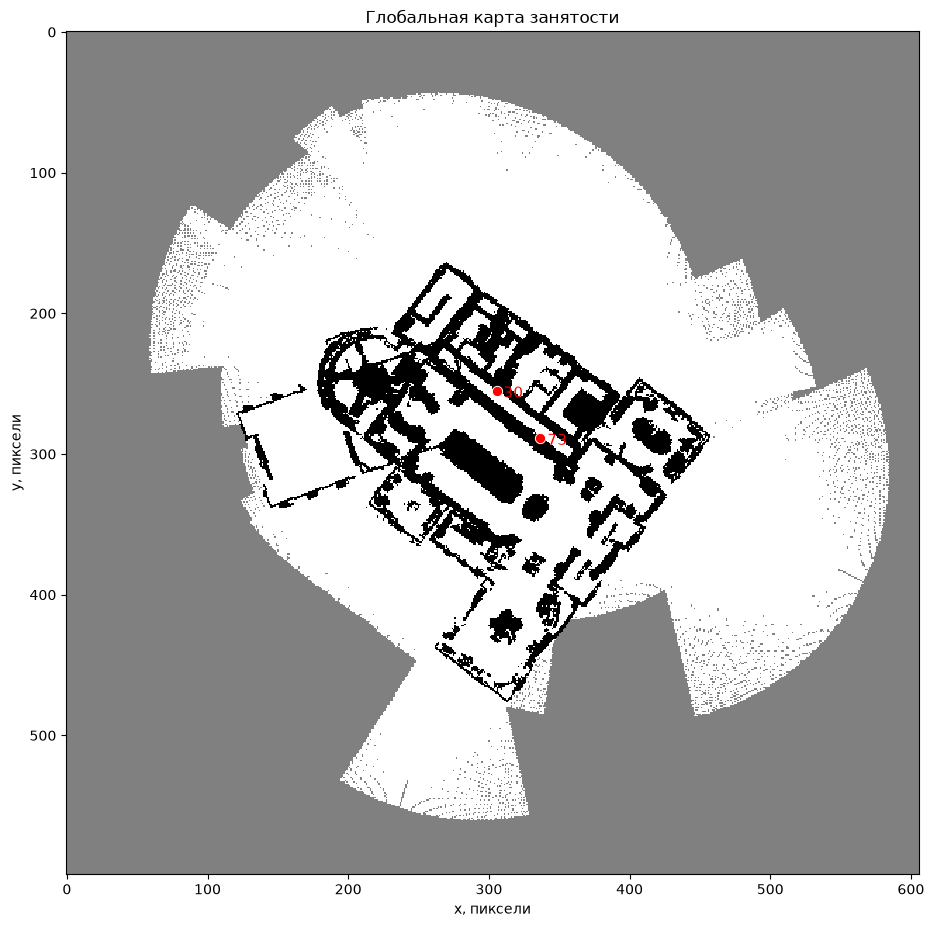

In [7]:
global_grid, global_params = stitch_global_map(topo_map)

print("Размер глобальной сетки:", global_grid.shape)
print("Разрешение, м/пиксель:", global_params["resolution"])
print(
    "Bounding box поз: x = [%.2f, %.2f], y = [%.2f, %.2f]"
    % (
        global_params["min_x"],
        global_params["max_x"],
        global_params["min_y"],
        global_params["max_y"],
    )
)
values, counts = np.unique(global_grid, return_counts=True)
print("Значения сетки:", {int(v): int(c) for v, c in zip(values, counts)})

occupancy_cmap = ListedColormap(["gray", "white", "black"])
occupancy_norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], occupancy_cmap.N)

fig, ax = plt.subplots(figsize=(11, 11))
ax.imshow(
    global_grid,
    cmap=occupancy_cmap,
    norm=occupancy_norm,
    interpolation="nearest",
)

for node_id in (73, 30):
    x, y, _ = topo_map.vertices[node_id]["pose"]
    row, col = world_to_global_pixel(x, y, global_params)
    ax.scatter(
        [col],
        [row],
        c="red",
        s=55,
        edgecolors="white",
        linewidths=0.7,
        zorder=5,
    )
    ax.annotate(
        str(node_id),
        (col, row),
        xytext=(5, -5),
        textcoords="offset points",
        color="red",
        fontsize=11,
        zorder=6,
    )

ax.set_title("Глобальная карта занятости")
ax.set_xlabel("x, пиксели")
ax.set_ylabel("y, пиксели")
plt.show()


## Этап 3. Попарная сшивка и раздутие препятствий

Карта соседа (`node_to`) переводится в систему координат текущей локации (`node_from`) по относительной позе ребра. Используется та же матричная схема с учётом того, что в локальной карте строка соответствует `x`, а столбец — `y`.

После слияния препятствия раздуваются на `r = 0.25` м эллиптическим структурным элементом `cv2.dilate`.


In [8]:
import math
import cv2
import numpy as np


def inflate_obstacles(grid, radius_m=0.25, resolution=0.1):
    r_pix = math.ceil(radius_m / resolution)
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (2 * r_pix + 1, 2 * r_pix + 1)
    )
    obstacles = (grid == 2).astype(np.uint8)
    inflated = cv2.dilate(obstacles, kernel)
    new_grid = grid.copy()
    new_grid[inflated == 1] = 2
    return new_grid


def warp_neighbor_to_current(topo_map, node_from, edge):
    node_to = int(edge["to"])
    res_from, grid_from = topo_map.load_local_map(node_from)
    res_to, grid_to = topo_map.load_local_map(node_to)
    x, y, theta = edge["pose"]
    matrix = (
        local_to_grid_matrix(grid_from.shape, res_from)
        @ pose_to_matrix(x, y, theta)
        @ grid_to_local_matrix(grid_to.shape, res_to)
    )
    warped = cv2.warpAffine(
        grid_to,
        matrix[:2].astype(np.float32),
        (grid_from.shape[1], grid_from.shape[0]),
        flags=cv2.INTER_NEAREST,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0,
    )
    return res_from, grid_from, warped


def stitch_local_pair(topo_map, node_from, edge):
    res_from, grid_from, warped = warp_neighbor_to_current(
        topo_map, node_from, edge
    )
    merged = np.maximum(grid_from, warped)
    return inflate_obstacles(merged, radius_m=0.25, resolution=res_from)


def pair_overlap_stats(topo_map, node_from, edge):
    _, grid_from, warped = warp_neighbor_to_current(topo_map, node_from, edge)
    both = (grid_from > 0) & (warped > 0)
    overlap = int(both.sum())
    if overlap == 0:
        return {"overlap": 0, "agreement": 0.0, "fraction": 0.0}
    agreement = float((grid_from[both] == warped[both]).mean())
    fraction = float(overlap / max(int((grid_from > 0).sum()), 1))
    return {
        "overlap": overlap,
        "agreement": agreement,
        "fraction": fraction,
    }


In [9]:
local_stitched_maps = {}
for node_from, vertex in topo_map.vertices.items():
    for edge in vertex["edges"]:
        node_to = int(edge["to"])
        local_stitched_maps[(node_from, node_to)] = stitch_local_pair(
            topo_map, node_from, edge
        )

print("Локально сшитых карт:", len(local_stitched_maps))
print(
    "Уникальных неориентированных рёбер:",
    len({tuple(sorted(key)) for key in local_stitched_maps}),
)

Локально сшитых карт: 252
Уникальных неориентированных рёбер: 126


Выбранные рёбра: [(81, 82), (33, 11), (73, 30)]
81 -> 82: overlap=2733 cells, agreement=0.921, fraction=0.602
33 -> 11: overlap=3814 cells, agreement=0.894, fraction=0.321
73 -> 30: overlap=1709 cells, agreement=0.915, fraction=0.634


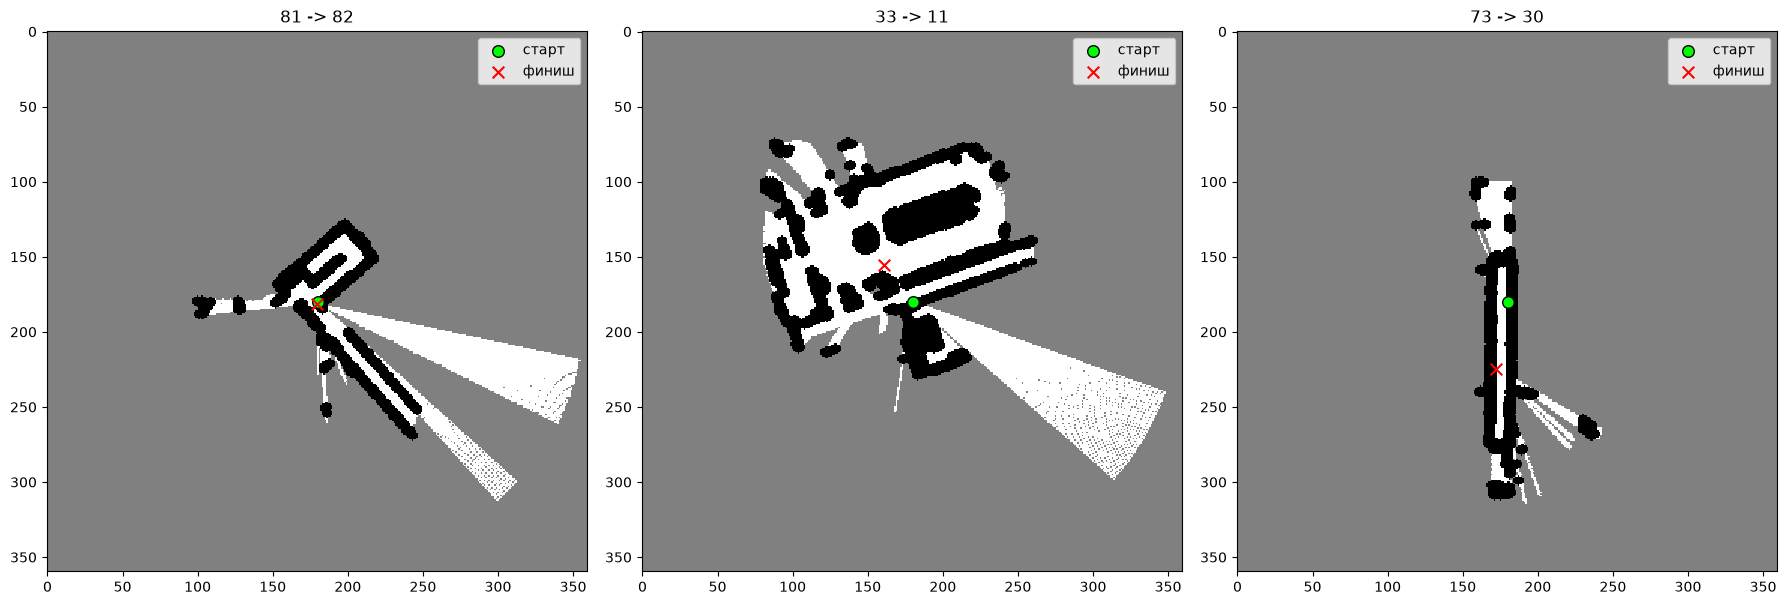

In [10]:
import random

random.seed(0)
sample_keys = random.sample(list(local_stitched_maps), 3)
print("Выбранные рёбра:", sample_keys)

for key in sample_keys:
    node_from, node_to = key
    edge = next(
        e for e in topo_map.vertices[node_from]["edges"] if int(e["to"]) == node_to
    )
    stats = pair_overlap_stats(topo_map, node_from, edge)
    print(
        f"{node_from} -> {node_to}: "
        f"overlap={stats['overlap']} cells, "
        f"agreement={stats['agreement']:.3f}, "
        f"fraction={stats['fraction']:.3f}"
    )

fig, axes = plt.subplots(1, len(sample_keys), figsize=(6 * len(sample_keys), 6))
if len(sample_keys) == 1:
    axes = [axes]

for ax, key in zip(axes, sample_keys):
    node_from, node_to = key
    grid = local_stitched_maps[key]
    edge = next(
        e for e in topo_map.vertices[node_from]["edges"] if int(e["to"]) == node_to
    )
    x, y, _ = edge["pose"]
    res, _ = topo_map.load_local_map(node_from)
    h, w = grid.shape
    start_row, start_col = h / 2.0, w / 2.0
    goal_row = start_row + x / res
    goal_col = start_col + y / res

    ax.imshow(
        grid,
        cmap=occupancy_cmap,
        norm=occupancy_norm,
        interpolation="nearest",
    )
    ax.scatter(
        [start_col],
        [start_row],
        c="lime",
        s=70,
        marker="o",
        edgecolors="black",
        label="старт",
    )
    ax.scatter([goal_col], [goal_row], c="red", s=70, marker="x", label="финиш")
    ax.set_title(f"{node_from} -> {node_to}")
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()


## Этап 3. Планирование путей алгоритмом A*

Реализуется A* на двумерной сетке занятости. Старт и финиш округляются до целых индексов, движение разрешено по восьми направлениям: прямые шаги имеют вес `1.0`, диагональные — `sqrt(2)`, эвристика — евклидово расстояние.

Проходимыми считаются клетки `grid == 1`; неизвестные клетки `0` и препятствия `2` запрещены. Дополнительно проверяется вариант `grid != 2`, в котором неизвестное пространство разрешено. Если старт или финиш выходит за границы карты либо попадает в препятствие, `astar_grid` возвращает `None`.

На локальных сшитых картах центр текущей локации и поза соседа после раздутия препятствий часто попадают в `2`. Поэтому, кроме строгого запуска, используется проекция старта и финиша на ближайшую проходимую клетку. В статистике приводятся оба результата: строгий показывает исходную постановку, с коррекцией — качество маршрута по самой карте.


In [11]:
import heapq
import math

import numpy as np


MOVES_8 = (
    (-1, -1, math.sqrt(2)),
    (-1, 0, 1.0),
    (-1, 1, math.sqrt(2)),
    (0, -1, 1.0),
    (0, 1, 1.0),
    (1, -1, math.sqrt(2)),
    (1, 0, 1.0),
    (1, 1, math.sqrt(2)),
)


def astar_grid(grid, start, goal, allow_unknown=False):
    rows, cols = grid.shape
    start_row = int(round(start[0]))
    start_col = int(round(start[1]))
    goal_row = int(round(goal[0]))
    goal_col = int(round(goal[1]))

    if not (
        0 <= start_row < rows
        and 0 <= start_col < cols
        and 0 <= goal_row < rows
        and 0 <= goal_col < cols
    ):
        return None

    passable = grid != 2 if allow_unknown else grid == 1
    if not passable[start_row, start_col] or not passable[goal_row, goal_col]:
        return None

    start_index = start_row * cols + start_col
    goal_index = goal_row * cols + goal_col
    if start_index == goal_index:
        return [(start_row, start_col)]

    g_score = np.full(rows * cols, np.inf, dtype=np.float64)
    parent = np.full(rows * cols, -1, dtype=np.int64)
    closed = np.zeros(rows * cols, dtype=bool)
    g_score[start_index] = 0.0

    heap = [
        (
            math.hypot(goal_row - start_row, goal_col - start_col),
            0.0,
            start_row,
            start_col,
        )
    ]

    while heap:
        _, current_g, row, col = heapq.heappop(heap)
        current_index = row * cols + col
        if closed[current_index]:
            continue
        if current_index == goal_index:
            path = []
            index = goal_index
            while True:
                path.append((index // cols, index % cols))
                if index == start_index:
                    break
                index = int(parent[index])
            return path[::-1]

        closed[current_index] = True

        for delta_row, delta_col, step_cost in MOVES_8:
            next_row = row + delta_row
            next_col = col + delta_col
            if not (0 <= next_row < rows and 0 <= next_col < cols):
                continue
            next_index = next_row * cols + next_col
            if closed[next_index] or not passable[next_row, next_col]:
                continue
            tentative_g = current_g + step_cost
            if tentative_g < g_score[next_index]:
                g_score[next_index] = tentative_g
                parent[next_index] = current_index
                heapq.heappush(
                    heap,
                    (
                        tentative_g
                        + math.hypot(goal_row - next_row, goal_col - next_col),
                        tentative_g,
                        next_row,
                        next_col,
                    ),
                )

    return None


def path_length_m(path, resolution):
    if path is None or len(path) < 2:
        return 0.0
    length = 0.0
    for (row_a, col_a), (row_b, col_b) in zip(path, path[1:]):
        length += math.hypot(row_b - row_a, col_b - col_a)
    return length * resolution


def nearest_passable_cell(grid, point, allow_unknown=False, max_radius=30):
    rows, cols = grid.shape
    start_row = int(round(point[0]))
    start_col = int(round(point[1]))
    if not (0 <= start_row < rows and 0 <= start_col < cols):
        return None

    passable = grid != 2 if allow_unknown else grid == 1
    if passable[start_row, start_col]:
        return (start_row, start_col)

    for radius in range(1, max_radius + 1):
        best_cell = None
        best_distance = None
        for delta_row in range(-radius, radius + 1):
            for delta_col in range(-radius, radius + 1):
                if max(abs(delta_row), abs(delta_col)) != radius:
                    continue
                row = start_row + delta_row
                col = start_col + delta_col
                if not (0 <= row < rows and 0 <= col < cols):
                    continue
                if not passable[row, col]:
                    continue
                distance = delta_row * delta_row + delta_col * delta_col
                if best_distance is None or distance < best_distance:
                    best_distance = distance
                    best_cell = (row, col)
        if best_cell is not None:
            return best_cell

    return None


def edge_pose(topo_map, node_from, node_to):
    edge = next(
        edge
        for edge in topo_map.vertices[node_from]["edges"]
        if int(edge["to"]) == node_to
    )
    return edge["pose"]


def plan_path(grid, start, goal, resolution, allow_unknown=False):
    strict_path = astar_grid(grid, start, goal, allow_unknown=allow_unknown)
    start_cell = nearest_passable_cell(
        grid, start, allow_unknown=allow_unknown
    )
    goal_cell = nearest_passable_cell(
        grid, goal, allow_unknown=allow_unknown
    )
    path = None
    if start_cell is not None and goal_cell is not None:
        path = astar_grid(
            grid, start_cell, goal_cell, allow_unknown=allow_unknown
        )
    return {
        "success": path is not None,
        "strict_success": strict_path is not None,
        "path": path,
        "length_m": path_length_m(path, resolution),
        "start": (int(round(start[0])), int(round(start[1]))),
        "goal": (int(round(goal[0])), int(round(goal[1]))),
        "start_cell": start_cell,
        "goal_cell": goal_cell,
    }


### Режимы проходимости и статистика этапа 3

Сначала сравниваются два строгих режима: `grid == 1` и `grid != 2`. Затем для обоих режимов выполняется планирование с проекцией старта и финиша на ближайшую проходимую клетку. Проекция не меняет карту и не «продавливает» препятствия: она только переносит начальную и конечную точки в свободную область, после чего A* ищет путь по разрешённым клеткам.

Для каждого ребра фиксируются факт нахождения пути, его длина в метрах и сам маршрут. Отдельно считается успешность по 252 направленным рёбрам и по 126 неориентированным парам: хотя бы в одну сторону и в обе стороны.


In [12]:
from IPython.display import Markdown, display


local_resolution = topo_map.load_local_map(next(iter(topo_map.vertices)))[0]


def local_start_goal(node_from, node_to, grid):
    x, y, _ = edge_pose(topo_map, node_from, node_to)
    height, width = grid.shape
    start = (height / 2.0, width / 2.0)
    goal = (
        start[0] + x / local_resolution,
        start[1] + y / local_resolution,
    )
    return start, goal


def plan_local_edges(allow_unknown):
    results = {}
    for (node_from, node_to), grid in local_stitched_maps.items():
        start, goal = local_start_goal(node_from, node_to, grid)
        results[(node_from, node_to)] = plan_path(
            grid, start, goal, local_resolution, allow_unknown
        )
    return results


def planning_stats(results, resolution):
    total = len(results)
    successes = [
        result for result in results.values() if result["success"]
    ]
    lengths = [result["length_m"] for result in successes]
    pairs = {}
    for (node_from, node_to), result in results.items():
        pairs.setdefault(
            tuple(sorted((node_from, node_to))), []
        ).append(result["success"])
    corrections = []
    for result in results.values():
        for original, cell in (
            (result["start"], result["start_cell"]),
            (result["goal"], result["goal_cell"]),
        ):
            if cell is not None:
                corrections.append(
                    math.hypot(cell[0] - original[0], cell[1] - original[1])
                    * resolution
                )
    return {
        "total": total,
        "strict": sum(
            result["strict_success"] for result in results.values()
        ),
        "success": len(successes),
        "success_rate": len(successes) / total,
        "pairs": len(pairs),
        "pairs_at_least_one": sum(
            any(values) for values in pairs.values()
        ),
        "pairs_both": sum(all(values) for values in pairs.values()),
        "mean_length_m": float(np.mean(lengths)) if lengths else 0.0,
        "median_length_m": (
            float(np.median(lengths)) if lengths else 0.0
        ),
        "max_length_m": float(np.max(lengths)) if lengths else 0.0,
        "zero_length": sum(length == 0.0 for length in lengths),
        "mean_correction_m": (
            float(np.mean(corrections)) if corrections else 0.0
        ),
        "max_correction_m": (
            float(np.max(corrections)) if corrections else 0.0
        ),
    }


def stats_table(title, stats):
    rows = [
        (
            "Направленных рёбер",
            str(stats["total"]),
        ),
        (
            "Строгий успех без коррекции",
            f"{stats['strict']} / {stats['total']} "
            f"({stats['strict'] / stats['total']:.1%})",
        ),
        (
            "Успех с коррекцией",
            f"{stats['success']} / {stats['total']} "
            f"({stats['success_rate']:.1%})",
        ),
        (
            "Success Rate",
            f"{stats['success_rate']:.3f}",
        ),
        (
            "Неориентированных пар",
            str(stats["pairs"]),
        ),
        (
            "Пар: хотя бы одна сторона",
            f"{stats['pairs_at_least_one']} / {stats['pairs']} "
            f"({stats['pairs_at_least_one'] / stats['pairs']:.1%})",
        ),
        (
            "Пар: обе стороны",
            f"{stats['pairs_both']} / {stats['pairs']} "
            f"({stats['pairs_both'] / stats['pairs']:.1%})",
        ),
        (
            "Средняя длина, м",
            f"{stats['mean_length_m']:.2f}",
        ),
        (
            "Медианная длина, м",
            f"{stats['median_length_m']:.2f}",
        ),
        (
            "Максимальная длина, м",
            f"{stats['max_length_m']:.2f}",
        ),
        (
            "Путей нулевой длины",
            str(stats["zero_length"]),
        ),
        (
            "Средняя коррекция, м",
            f"{stats['mean_correction_m']:.2f}",
        ),
        (
            "Максимальная коррекция, м",
            f"{stats['max_correction_m']:.2f}",
        ),
    ]
    lines = [
        f"**{title}**",
        "",
        "| Показатель | Значение |",
        "|---|---:|",
    ]
    lines.extend(f"| {name} | {value} |" for name, value in rows)
    return "\n".join(lines)


local_results = plan_local_edges(False)
local_results_unknown = plan_local_edges(True)
local_stats = planning_stats(local_results, local_resolution)
local_stats_unknown = planning_stats(
    local_results_unknown, local_resolution
)

local_bad_start = 0
local_bad_goal = 0
local_both_free = 0
for (node_from, node_to), grid in local_stitched_maps.items():
    start, goal = local_start_goal(node_from, node_to, grid)
    start_cell = (int(round(start[0])), int(round(start[1])))
    goal_cell = (int(round(goal[0])), int(round(goal[1])))
    if grid[start_cell] != 1:
        local_bad_start += 1
    if grid[goal_cell] != 1:
        local_bad_goal += 1
    if grid[start_cell] == 1 and grid[goal_cell] == 1:
        local_both_free += 1

print(
    f"Локальные карты: старт не в grid == 1 у {local_bad_start} рёбер, "
    f"финиш — у {local_bad_goal}, оба свободны у {local_both_free}."
)
print(
    f"Строгий A*: grid == 1 — {local_stats['strict']} / 252, "
    f"grid != 2 — {local_stats_unknown['strict']} / 252."
)

display(Markdown(stats_table("Этап 3, grid == 1", local_stats)))
display(
    Markdown(stats_table("Этап 3, grid != 2", local_stats_unknown))
)


Локальные карты: старт не в grid == 1 у 185 рёбер, финиш — у 186, оба свободны у 24.
Строгий A*: grid == 1 — 22 / 252, grid != 2 — 22 / 252.


**Этап 3, grid == 1**

| Показатель | Значение |
|---|---:|
| Направленных рёбер | 252 |
| Строгий успех без коррекции | 22 / 252 (8.7%) |
| Успех с коррекцией | 234 / 252 (92.9%) |
| Success Rate | 0.929 |
| Неориентированных пар | 126 |
| Пар: хотя бы одна сторона | 119 / 126 (94.4%) |
| Пар: обе стороны | 115 / 126 (91.3%) |
| Средняя длина, м | 1.68 |
| Медианная длина, м | 0.95 |
| Максимальная длина, м | 10.69 |
| Путей нулевой длины | 20 |
| Средняя коррекция, м | 0.16 |
| Максимальная коррекция, м | 0.71 |

**Этап 3, grid != 2**

| Показатель | Значение |
|---|---:|
| Направленных рёбер | 252 |
| Строгий успех без коррекции | 22 / 252 (8.7%) |
| Успех с коррекцией | 240 / 252 (95.2%) |
| Success Rate | 0.952 |
| Неориентированных пар | 126 |
| Пар: хотя бы одна сторона | 122 / 126 (96.8%) |
| Пар: обе стороны | 118 / 126 (93.7%) |
| Средняя длина, м | 1.96 |
| Медианная длина, м | 0.98 |
| Максимальная длина, м | 21.10 |
| Путей нулевой длины | 20 |
| Средняя коррекция, м | 0.16 |
| Максимальная коррекция, м | 0.71 |

### Примеры локального планирования

Показаны четыре успешных маршрута и два случая, где путь не найден. Зелёный круг — старт после проекции на свободную клетку, красный крест — финиш. На неудачных примерах светло-синим выделена компонента свободного пространства, доступная из старта: финиш находится в другой компоненте, поэтому A* не может до него добраться.


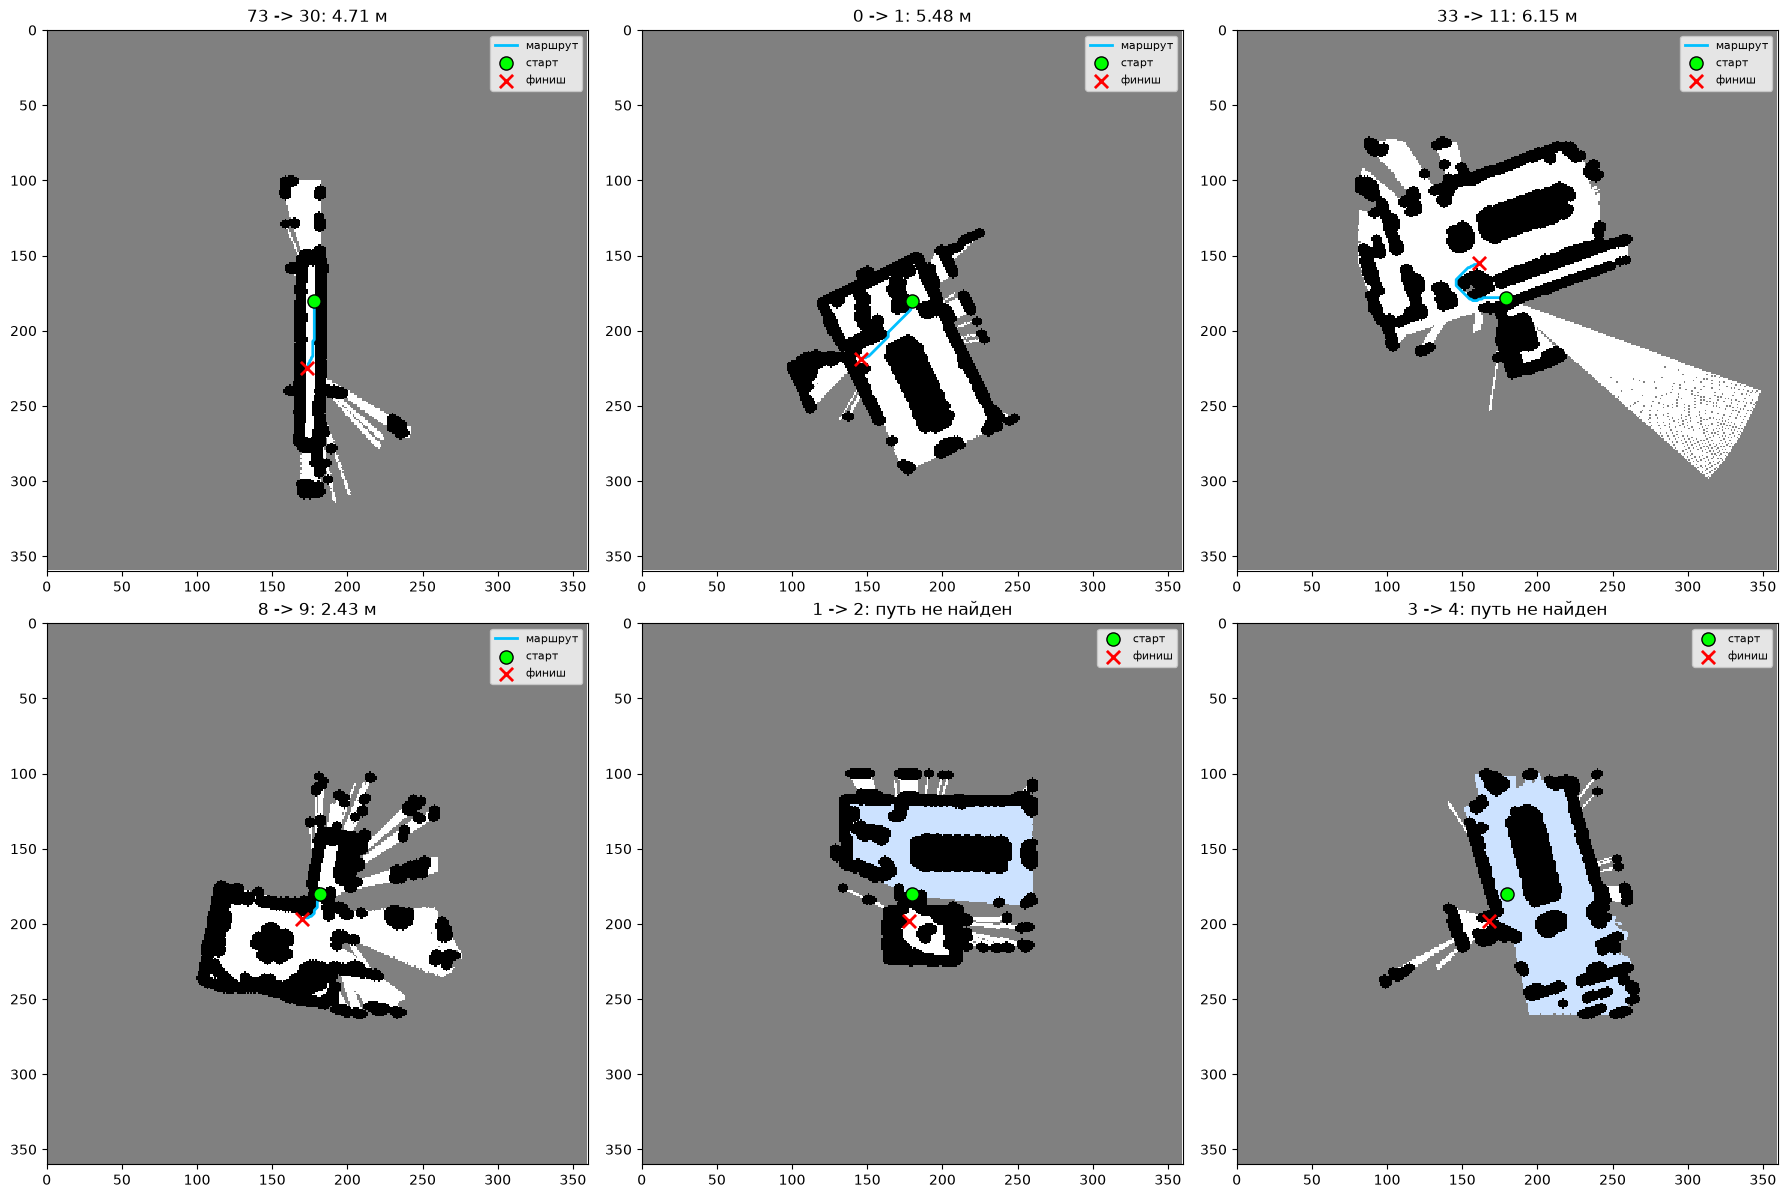

In [13]:
local_examples = [
    (73, 30),
    (0, 1),
    (33, 11),
    (8, 9),
    (1, 2),
    (3, 4),
]

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for ax, (node_from, node_to) in zip(axes.ravel(), local_examples):
    grid = local_stitched_maps[(node_from, node_to)]
    result = local_results[(node_from, node_to)]
    ax.imshow(
        grid,
        cmap=occupancy_cmap,
        norm=occupancy_norm,
        interpolation="nearest",
    )

    if result["success"]:
        path_rows = [cell[0] for cell in result["path"]]
        path_cols = [cell[1] for cell in result["path"]]
        ax.plot(
            path_cols,
            path_rows,
            color="deepskyblue",
            linewidth=2.0,
            label="маршрут",
        )
        title = (
            f"{node_from} -> {node_to}: "
            f"{result['length_m']:.2f} м"
        )
    else:
        start_cell = result["start_cell"]
        if start_cell is not None:
            _, labels = cv2.connectedComponents(
                (grid == 1).astype(np.uint8), connectivity=8
            )
            component = labels == labels[start_cell[0], start_cell[1]]
            overlay = np.zeros((*grid.shape, 4), dtype=float)
            overlay[component] = (0.2, 0.55, 1.0, 0.25)
            ax.imshow(overlay, interpolation="nearest")
        title = f"{node_from} -> {node_to}: путь не найден"

    start_cell = (
        result["start_cell"]
        if result["start_cell"] is not None
        else result["start"]
    )
    goal_cell = (
        result["goal_cell"]
        if result["goal_cell"] is not None
        else result["goal"]
    )
    ax.scatter(
        [start_cell[1]],
        [start_cell[0]],
        c="lime",
        s=90,
        edgecolors="black",
        zorder=5,
        label="старт",
    )
    ax.scatter(
        [goal_cell[1]],
        [goal_cell[0]],
        c="red",
        marker="x",
        s=90,
        linewidths=2.0,
        zorder=5,
        label="финиш",
    )
    ax.set_title(title)
    ax.set_xlim(0, grid.shape[1])
    ax.set_ylim(grid.shape[0], 0)
    ax.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()


## Этап 4. Глобальное планирование по истинным позам

Глобальная карта раздувается тем же структурным элементом `r = 0.25` м. Затем для каждого из 252 рёбер истинные позы вершин `pose_for_visualization` переводятся в пиксели глобальной сетки через `world_to_global_pixel`, после чего запускается тот же `astar_grid`.

Планирование выполняется на раздутой карте; для сравнения с этапом 3 сохраняются строгий результат и результат с проекцией старта и финиша на ближайшую свободную клетку.


Значения раздутой глобальной сетки: {0: 205576, 1: 119843, 2: 37575}
Компонент свободного пространства: 39


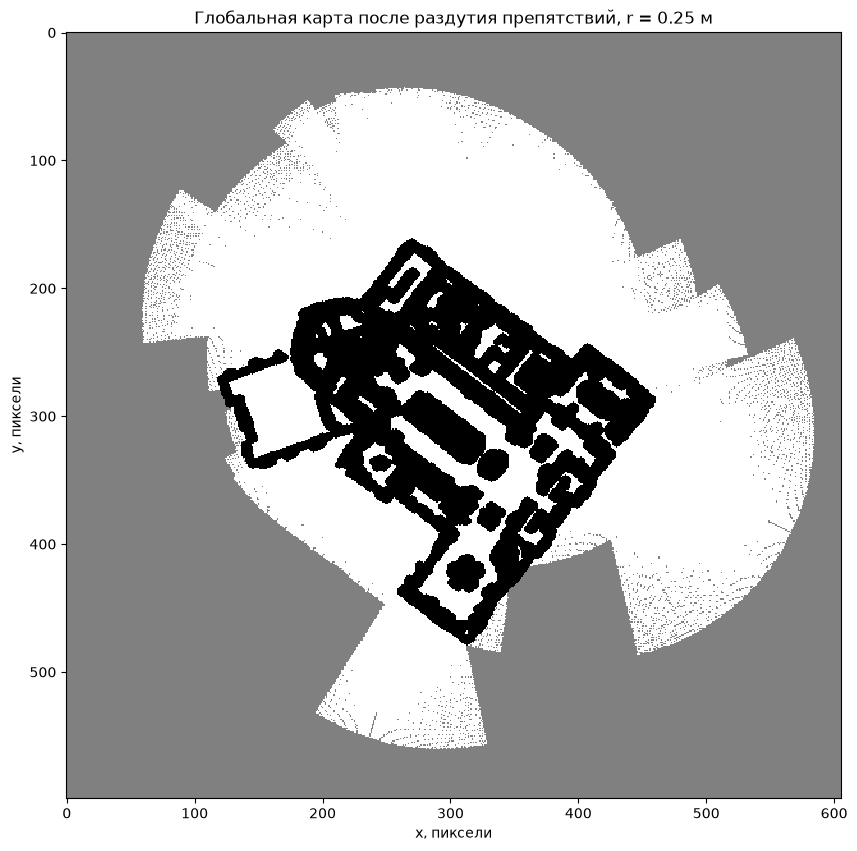

In [14]:
global_inflated = inflate_obstacles(
    global_grid,
    radius_m=0.25,
    resolution=global_params["resolution"],
)

values, counts = np.unique(global_inflated, return_counts=True)
print(
    "Значения раздутой глобальной сетки:",
    {int(value): int(count) for value, count in zip(values, counts)},
)

free_components, _ = cv2.connectedComponents(
    (global_inflated == 1).astype(np.uint8), connectivity=8
)
print("Компонент свободного пространства:", free_components - 1)

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(
    global_inflated,
    cmap=occupancy_cmap,
    norm=occupancy_norm,
    interpolation="nearest",
)
ax.set_title("Глобальная карта после раздутия препятствий, r = 0.25 м")
ax.set_xlabel("x, пиксели")
ax.set_ylabel("y, пиксели")
plt.show()


### Статистика глобального планирования

Для всех рёбер графа запускается A* на раздутой глобальной карте. В таблице ниже результаты этапа 4 сравниваются с этапом 3. Дополнительно проверяется режим `grid != 2`; на глобальной карте он даёт тот же результат, потому что центры вершин попадают именно в раздутые препятствия `2`, а не в неизвестные клетки `0`.


In [15]:
def plan_global_edges(allow_unknown):
    results = {}
    for node_from, vertex in topo_map.vertices.items():
        start_x, start_y, _ = vertex["pose"]
        start = world_to_global_pixel(start_x, start_y, global_params)
        for edge in vertex["edges"]:
            node_to = int(edge["to"])
            goal_x, goal_y, _ = topo_map.vertices[node_to]["pose"]
            goal = world_to_global_pixel(
                goal_x, goal_y, global_params
            )
            results[(node_from, node_to)] = plan_path(
                global_inflated,
                start,
                goal,
                global_params["resolution"],
                allow_unknown,
            )
    return results


global_results = plan_global_edges(False)
global_results_unknown = plan_global_edges(True)
global_stats = planning_stats(
    global_results, global_params["resolution"]
)
global_stats_unknown = planning_stats(
    global_results_unknown, global_params["resolution"]
)

global_bad_start = 0
global_bad_goal = 0
global_both_free = 0
for node_from, vertex in topo_map.vertices.items():
    start_x, start_y, _ = vertex["pose"]
    start = world_to_global_pixel(start_x, start_y, global_params)
    start_cell = (int(round(start[0])), int(round(start[1])))
    start_is_free = global_inflated[start_cell] == 1
    for edge in vertex["edges"]:
        node_to = int(edge["to"])
        goal_x, goal_y, _ = topo_map.vertices[node_to]["pose"]
        goal = world_to_global_pixel(goal_x, goal_y, global_params)
        goal_cell = (int(round(goal[0])), int(round(goal[1])))
        goal_is_free = global_inflated[goal_cell] == 1
        if not start_is_free:
            global_bad_start += 1
        if not goal_is_free:
            global_bad_goal += 1
        if start_is_free and goal_is_free:
            global_both_free += 1

print(
    f"Глобальная карта: старт не в grid == 1 у {global_bad_start} "
    f"рёбер, финиш — у {global_bad_goal}, "
    f"оба свободны у {global_both_free}."
)
print(
    f"Строгий A*: grid == 1 — {global_stats['strict']} / 252, "
    f"grid != 2 — {global_stats_unknown['strict']} / 252."
)

table_header = (
    "| Метрика | Этап 3, grid == 1 | Этап 3, grid != 2 | "
    "Этап 4, grid == 1 | Этап 4, grid != 2 |"
)
table_separator = "|---|---:|---:|---:|---:|"
table_rows = [
    (
        "Строгий успех без коррекции",
        local_stats,
        lambda stats: (
            f"{stats['strict']} / {stats['total']} "
            f"({stats['strict'] / stats['total']:.1%})"
        ),
    ),
    (
        "Успех с коррекцией",
        local_stats,
        lambda stats: (
            f"{stats['success']} / {stats['total']} "
            f"({stats['success_rate']:.1%})"
        ),
    ),
    (
        "Success Rate",
        local_stats,
        lambda stats: f"{stats['success_rate']:.3f}",
    ),
    (
        "Пар: хотя бы одна сторона",
        local_stats,
        lambda stats: (
            f"{stats['pairs_at_least_one']} / {stats['pairs']} "
            f"({stats['pairs_at_least_one'] / stats['pairs']:.1%})"
        ),
    ),
    (
        "Пар: обе стороны",
        local_stats,
        lambda stats: (
            f"{stats['pairs_both']} / {stats['pairs']} "
            f"({stats['pairs_both'] / stats['pairs']:.1%})"
        ),
    ),
    (
        "Средняя длина, м",
        local_stats,
        lambda stats: f"{stats['mean_length_m']:.2f}",
    ),
    (
        "Медианная длина, м",
        local_stats,
        lambda stats: f"{stats['median_length_m']:.2f}",
    ),
    (
        "Путей нулевой длины",
        local_stats,
        lambda stats: str(stats["zero_length"]),
    ),
    (
        "Максимальная коррекция, м",
        local_stats,
        lambda stats: f"{stats['max_correction_m']:.2f}",
    ),
]

all_stats = [
    local_stats,
    local_stats_unknown,
    global_stats,
    global_stats_unknown,
]
lines = [table_header, table_separator]
for name, _, formatter in table_rows:
    values = [formatter(stats) for stats in all_stats]
    lines.append(
        f"| {name} | " + " | ".join(values) + " |"
    )
display(Markdown("**Сравнение этапов 3 и 4**\n\n" + "\n".join(lines)))


Глобальная карта: старт не в grid == 1 у 215 рёбер, финиш — у 215, оба свободны у 20.
Строгий A*: grid == 1 — 18 / 252, grid != 2 — 18 / 252.


**Сравнение этапов 3 и 4**

| Метрика | Этап 3, grid == 1 | Этап 3, grid != 2 | Этап 4, grid == 1 | Этап 4, grid != 2 |
|---|---:|---:|---:|---:|
| Строгий успех без коррекции | 22 / 252 (8.7%) | 22 / 252 (8.7%) | 18 / 252 (7.1%) | 18 / 252 (7.1%) |
| Успех с коррекцией | 234 / 252 (92.9%) | 240 / 252 (95.2%) | 158 / 252 (62.7%) | 158 / 252 (62.7%) |
| Success Rate | 0.929 | 0.952 | 0.627 | 0.627 |
| Пар: хотя бы одна сторона | 119 / 126 (94.4%) | 122 / 126 (96.8%) | 79 / 126 (62.7%) | 79 / 126 (62.7%) |
| Пар: обе стороны | 115 / 126 (91.3%) | 118 / 126 (93.7%) | 79 / 126 (62.7%) | 79 / 126 (62.7%) |
| Средняя длина, м | 1.68 | 1.96 | 1.89 | 1.89 |
| Медианная длина, м | 0.95 | 0.98 | 0.42 | 0.42 |
| Путей нулевой длины | 20 | 20 | 34 | 34 |
| Максимальная коррекция, м | 0.71 | 0.71 | 1.13 | 1.13 |

### Примеры глобальных маршрутов

На крупных планах показаны найденные пути между соседними вершинами. Координаты вырезаны по bounding box маршрута с отступом, чтобы были видны стены и конфигурация прохода.


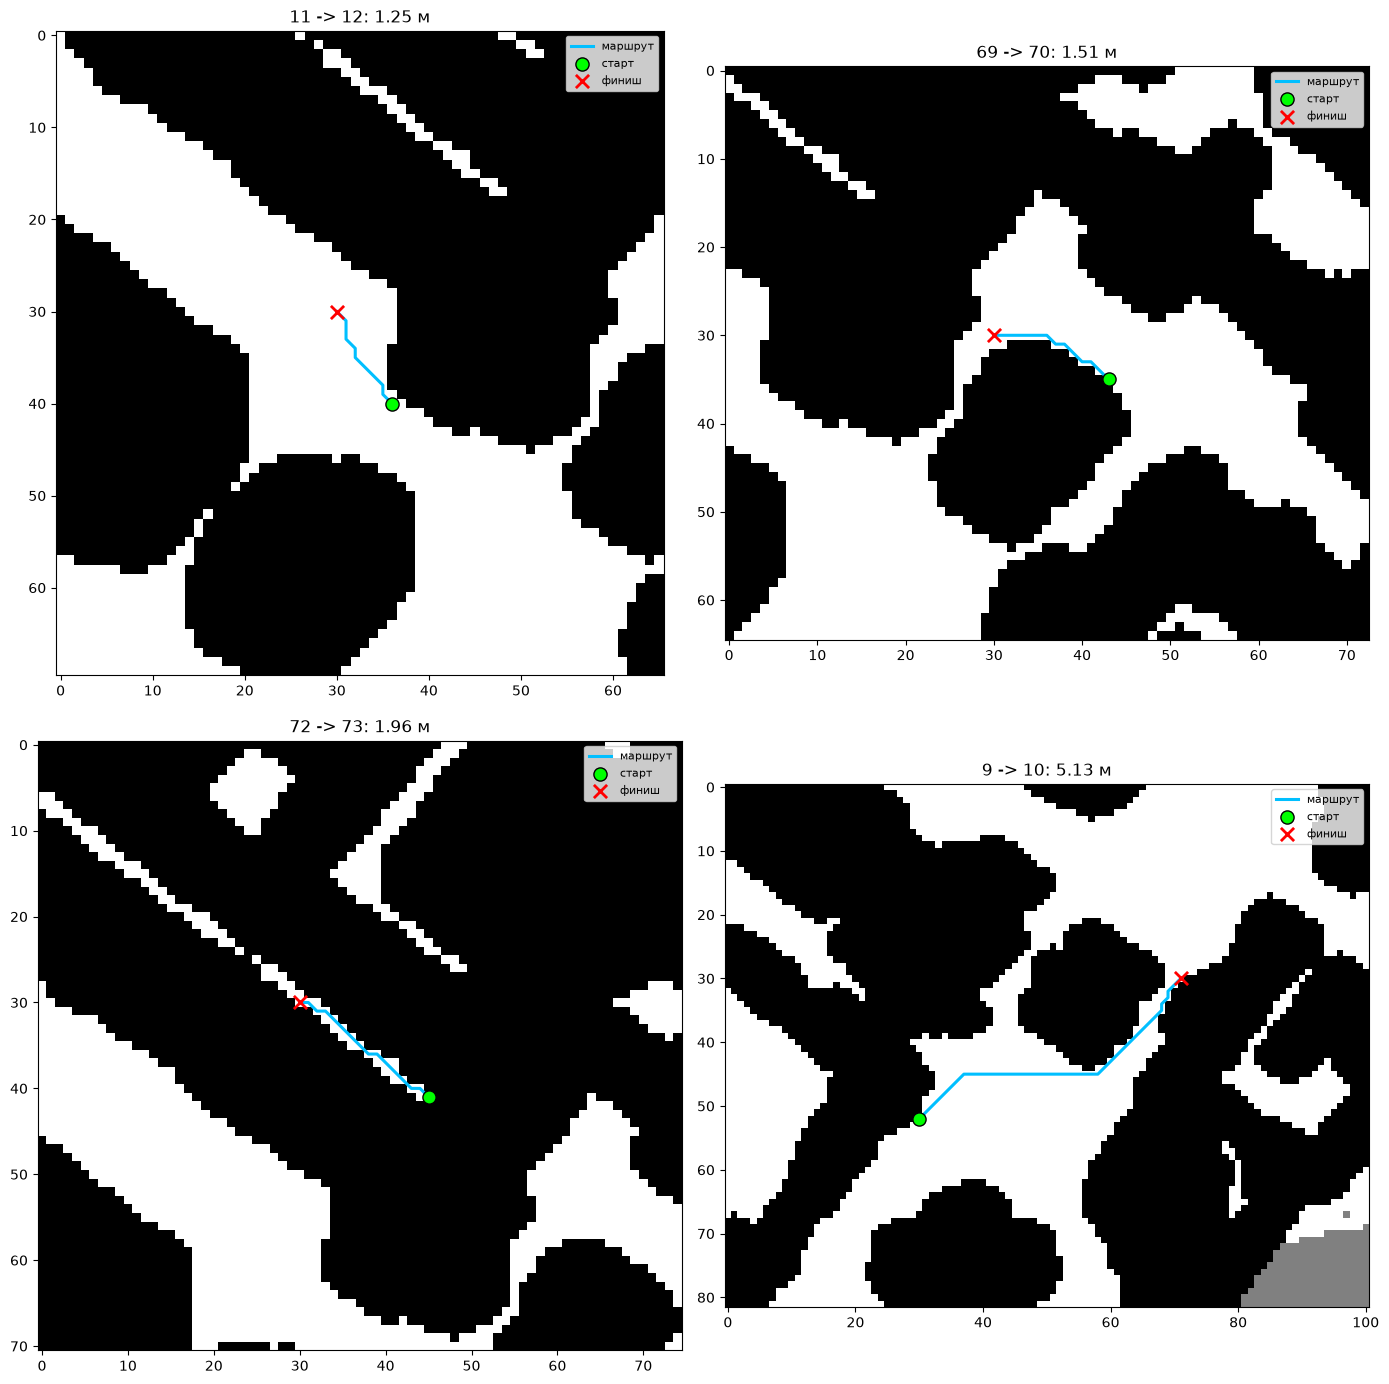

In [16]:
global_examples = [(11, 12), (69, 70), (72, 73), (9, 10)]

fig, axes = plt.subplots(2, 2, figsize=(14, 14))

for ax, key in zip(axes.ravel(), global_examples):
    result = global_results[key]
    if not result["success"]:
        ax.set_title(f"{key[0]} -> {key[1]}: путь не найден")
        ax.axis("off")
        continue

    rows = [cell[0] for cell in result["path"]]
    cols = [cell[1] for cell in result["path"]]
    margin = 30
    row_min = max(0, min(rows) - margin)
    row_max = min(global_inflated.shape[0], max(rows) + margin)
    col_min = max(0, min(cols) - margin)
    col_max = min(global_inflated.shape[1], max(cols) + margin)
    crop = global_inflated[row_min:row_max, col_min:col_max]

    ax.imshow(
        crop,
        cmap=occupancy_cmap,
        norm=occupancy_norm,
        interpolation="nearest",
    )
    ax.plot(
        [col - col_min for col in cols],
        [row - row_min for row in rows],
        color="deepskyblue",
        linewidth=2.2,
        label="маршрут",
    )
    ax.scatter(
        [result["start_cell"][1] - col_min],
        [result["start_cell"][0] - row_min],
        c="lime",
        s=90,
        edgecolors="black",
        zorder=5,
        label="старт",
    )
    ax.scatter(
        [result["goal_cell"][1] - col_min],
        [result["goal_cell"][0] - row_min],
        c="red",
        marker="x",
        s=90,
        linewidths=2.0,
        zorder=5,
        label="финиш",
    )
    ax.set_title(
        f"{key[0]} -> {key[1]}: {result['length_m']:.2f} м"
    )
    ax.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()


### Все построенные маршруты на глобальной карте

Ниже все успешные маршруты этапа 4 наложены на раздутую глобальную карту. Видно, что основная часть путей проходит по коридорам, но часть маршрутов вынуждена обходить разрывы свободного пространства, возникшие при максимизации локальных карт.


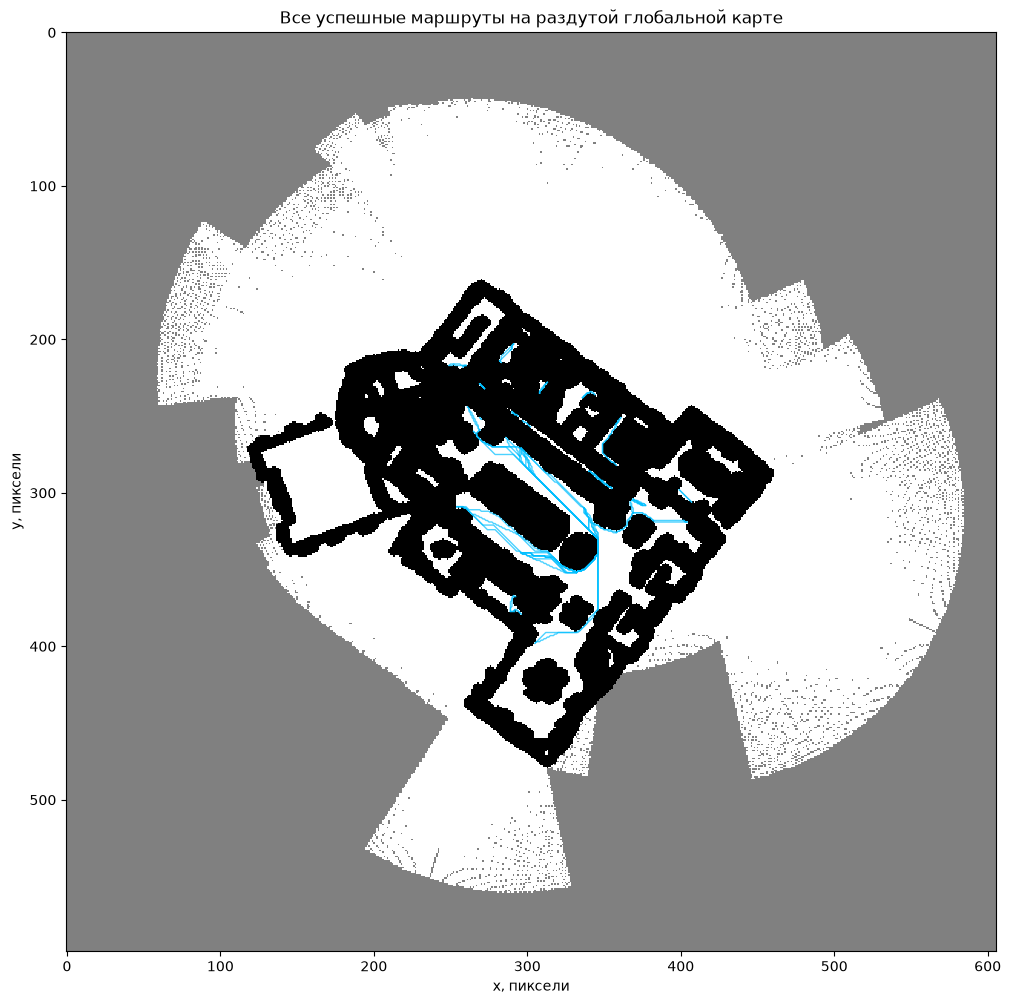

In [17]:
fig, ax = plt.subplots(figsize=(12, 12))
ax.imshow(
    global_inflated,
    cmap=occupancy_cmap,
    norm=occupancy_norm,
    interpolation="nearest",
)

for result in global_results.values():
    if not result["success"]:
        continue
    rows = [cell[0] for cell in result["path"]]
    cols = [cell[1] for cell in result["path"]]
    ax.plot(
        cols,
        rows,
        color="deepskyblue",
        linewidth=1.0,
        alpha=0.7,
    )

ax.set_title(
    "Все успешные маршруты на раздутой глобальной карте"
)
ax.set_xlabel("x, пиксели")
ax.set_ylabel("y, пиксели")
plt.show()


## Выводы

**Строгая постановка.** Если не корректировать старт и финиш, A* находит путь лишь в `22 / 252` случаях на локальных картах (`8.7%`) и в `18 / 252` на глобальной (`7.1%`). Причина не в самом алгоритме, а в раздутии препятствий: после `r = 0.25` м центры многих вершин оказываются в клетках `2`. На локальных картах старт не свободен у 185 рёбер, финиш — у 186, оба свободны только у 24; на глобальной карте старт и финиш не свободны у 215 рёбер, оба свободны у 20. Поэтому строгая успешность почти не зависит от режима `grid == 1` или `grid != 2`: основная причина отказа — не неизвестные клетки, а раздутые стены.

**С коррекцией старта и финиша.** Проекция на ближайшую свободную клетку меняет картину: на локальных картах успех составляет `234 / 252` (`92.9%`) для `grid == 1` и `240 / 252` (`95.2%`) для `grid != 2`. По неориентированным парам это `119 / 126` и `122 / 126` соответственно, причём в обе стороны проходятся `115 / 126` и `118 / 126` пар. Средняя длина локального маршрута — около `1.68` м, медианная — `0.95` м, максимальная коррекция точки — `0.71` м. Успешность выше для `grid != 2`, потому что неизвестные клетки на краю карты дают дополнительные допустимые точки старта и финиша; основной режим `grid == 1` выбран как более безопасный, поскольку движение через неизвестное пространство не гарантирует отсутствия препятствий.

**Глобальная карта.** На этапе 4 успех с коррекцией — `158 / 252` (`62.7%`), по парам — `79 / 126` (`62.7%`), причём успех симметричен: если путь находится в одну сторону, он находится и в обратную. Средняя длина — `1.89` м, медианная — `0.42` м, максимальная — `23.59` м. Свободное пространство глобальной карты распадается на `39` компонент. Часть маршрутов обходит препятствия и получается заметно длиннее прямого расстояния: например, для `0 -> 1` путь составляет `23.59` м при `4.96` м по прямой. Это следствие поэлементной максимизации: клетка, занятая хотя бы на одной локальной карте, становится препятствием `2`, поэтому при небольших ошибках поз и несовпадении наблюдений стены «сшиваются» с разрывами и перекрывают коридоры.

**Почему локальная сшивка успешнее.** На этапе 3 каждая карта строится только из двух наблюдений — текущей локации и соседа. Ошибка относительной позы ребра влияет на одну пару, а не на всю карту, поэтому свободная зона вокруг общего коридора чаще остаётся связной. Максимизация здесь тоже может смещать стены и сужать проходы, но число накладываемых карт мало, и компоненты свободного пространства не успевают раздробиться так сильно, как на глобальной карте из 95 наблюдений. Кроме того, локальный маршрут короткий: средняя длина `1.68` м против `1.89` м, а большинство целей находятся в пределах одной-двух карт.

**Почему глобальная карта точнее, но хуже проходит по связности.** Глобальная сшивка использует истинные позы `pose_for_visualization`, поэтому убирает накопленный дрейф относительных поз и даёт единую метрическую систему координат. Это важно для длинных маршрутов и для согласованных координат вершин. Однако та же глобальная карта накапливает противоречия между 95 локальными наблюдениями: максимизация занятости превращает любые расхождения в препятствия, а раздутие `r = 0.25` м дополнительно закрывает узкие места. В результате глобальный Success Rate ниже, а часть найденных путей представляет собой обходы, а не кратчайшие маршруты.

**Компромисс.** Топологический подход с локальной сшивкой вычислительно дешевле: планирование выполняется на карте `360 × 360` для одной пары, не требует строить и хранить глобальную сетку и лучше сохраняет локальную проходимость. Но он не даёт глобально согласованных координат и накапливает ошибку при переходе между вершинами. Глобальная метрическая карта обеспечивает единую систему координат и более точные длинные маршруты, но требует полной сшивки, чувствительна к ошибкам поз, наложению стен и раздутию препятствий, а также может терять связность коридоров. Практический компромисс — использовать локальные карты для быстрого планирования внутри ребра и глобальную карту для проверки маршрута и координации, при необходимости ослабляя максимизацию занятости или уменьшая радиус раздутия там, где проходы узкие.
